## Q1: You are building a morphological analyzer for nouns in English language using a finite 
state transducer. ‘s’ suffix is concatenated to regular nouns to create plural forms. But 
there is an exception to it when the following occurs: 
A noun ending in s, x, z, ch, or sh forms its plural by adding es. 
Design an FST that can produce all singular and plural forms of nouns as stated above. 
Use +SG for singular features, +PL for plural features, and +N for noun features. Show 
all states and transition table as well. 

In [1]:
import json
import math
from collections import Counter
from pathlib import Path

LAB_DIR = Path.cwd() if Path.cwd().name.lower() == "lab 8" else Path.cwd() / "Lab 8"
OUTPUT_DIR = LAB_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def save_json(filename, result):
    path = OUTPUT_DIR / filename
    path.write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    return path


def is_sibilant(stem):
    return stem.endswith(("s", "x", "z", "ch", "sh"))


def realize_noun(stem, features):
    if features == "+N+SG":
        return stem
    if features == "+N+PL":
        return stem + ("es" if is_sibilant(stem) else "s")
    raise ValueError("Features must be +N+SG or +N+PL")


states = ["q0", "q_regular", "q_sibilant", "q_regular_noun", "q_sibilant_noun", "q_final"]
transition_table = [
    {"from": "q0", "input": "regular stem", "output": "copy stem", "to": "q_regular"},
    {"from": "q0", "input": "stem ending s, x, z, ch, or sh", "output": "copy stem", "to": "q_sibilant"},
    {"from": "q_regular", "input": "+N", "output": "epsilon", "to": "q_regular_noun"},
    {"from": "q_sibilant", "input": "+N", "output": "epsilon", "to": "q_sibilant_noun"},
    {"from": "q_regular_noun", "input": "+SG", "output": "epsilon", "to": "q_final"},
    {"from": "q_sibilant_noun", "input": "+SG", "output": "epsilon", "to": "q_final"},
    {"from": "q_regular_noun", "input": "+PL", "output": "s", "to": "q_final"},
    {"from": "q_sibilant_noun", "input": "+PL", "output": "es", "to": "q_final"},
]

examples = [
    {"lexical_input": stem + features, "surface_output": realize_noun(stem, features)}
    for stem in ["cat", "bus", "box", "buzz", "church", "dish"]
    for features in ["+N+SG", "+N+PL"]
]

q1_result = {"states": states, "start_state": "q0", "final_state": "q_final", "transition_table": transition_table, "examples": examples}
print(json.dumps(q1_result, indent=2))
_ = save_json("q1_fst_results.json", q1_result)


{
  "states": [
    "q0",
    "q_regular",
    "q_sibilant",
    "q_regular_noun",
    "q_sibilant_noun",
    "q_final"
  ],
  "start_state": "q0",
  "final_state": "q_final",
  "transition_table": [
    {
      "from": "q0",
      "input": "regular stem",
      "output": "copy stem",
      "to": "q_regular"
    },
    {
      "from": "q0",
      "input": "stem ending s, x, z, ch, or sh",
      "output": "copy stem",
      "to": "q_sibilant"
    },
    {
      "from": "q_regular",
      "input": "+N",
      "output": "epsilon",
      "to": "q_regular_noun"
    },
    {
      "from": "q_sibilant",
      "input": "+N",
      "output": "epsilon",
      "to": "q_sibilant_noun"
    },
    {
      "from": "q_regular_noun",
      "input": "+SG",
      "output": "epsilon",
      "to": "q_final"
    },
    {
      "from": "q_sibilant_noun",
      "input": "+SG",
      "output": "epsilon",
      "to": "q_final"
    },
    {
      "from": "q_regular_noun",
      "input": "+PL",
      "output": "s

## Q2:  Consider the following corpus: 
low lower low lower lowest 
low lowest low lowest 
low new 
new new newer newer 
new 
Apply the wordpiece algorithm for 2 merges. What will be tokenization of the word 
newest ?

In [2]:
def split_into_wordpieces(word):
    return [word[0]] + ["##" + character for character in word[1:]]


def count_wordpiece_pairs(word_counts, sequences):
    pair_counts = Counter()
    token_counts = Counter()
    for word, count in word_counts.items():
        pieces = sequences[word]
        for piece in pieces:
            token_counts[piece] += count
        for left, right in zip(pieces, pieces[1:]):
            pair_counts[(left, right)] += count
    return pair_counts, token_counts


def merge_pair(sequence, pair):
    merged = []
    index = 0
    while index < len(sequence):
        if index + 1 < len(sequence) and (sequence[index], sequence[index + 1]) == pair:
            merged.append(sequence[index] + sequence[index + 1][2:])
            index += 2
        else:
            merged.append(sequence[index])
            index += 1
    return merged


word_counts = Counter([
    "low", "lower", "low", "lower", "lowest",
    "low", "lowest", "low", "lowest",
    "low", "new",
    "new", "new", "newer", "newer",
    "new",
])
sequences = {word: split_into_wordpieces(word) for word in word_counts}
merges = []

for _ in range(2):
    pair_counts, token_counts = count_wordpiece_pairs(word_counts, sequences)
    scores = {
        pair: count / (token_counts[pair[0]] * token_counts[pair[1]])
        for pair, count in pair_counts.items()
    }
    best_pair = max(scores, key=scores.get)
    merges.append({
        "pair": list(best_pair),
        "frequency": pair_counts[best_pair],
        "score": scores[best_pair],
    })
    sequences = {word: merge_pair(pieces, best_pair) for word, pieces in sequences.items()}

newest_pieces = split_into_wordpieces("newest")
for merge in merges:
    newest_pieces = merge_pair(newest_pieces, tuple(merge["pair"]))

q2_result = {
    "pair_score": "pair_frequency / (left_piece_frequency * right_piece_frequency)",
    "word_frequencies": dict(word_counts),
    "merges": merges,
    "newest_tokenization": newest_pieces,
}
print(json.dumps(q2_result, indent=2))
_ = save_json("q2_wordpiece_results.json", q2_result)


{
  "pair_score": "pair_frequency / (left_piece_frequency * right_piece_frequency)",
  "word_frequencies": {
    "low": 5,
    "lower": 2,
    "lowest": 3,
    "new": 4,
    "newer": 2
  },
  "merges": [
    {
      "pair": [
        "##s",
        "##t"
      ],
      "frequency": 3,
      "score": 0.3333333333333333
    },
    {
      "pair": [
        "l",
        "##o"
      ],
      "frequency": 10,
      "score": 0.1
    }
  ],
  "newest_tokenization": [
    "n",
    "##e",
    "##w",
    "##e",
    "##st"
  ]
}


## Q3:Consider the following sentences in the toy dataset: 
cat dog animal 
cat cat pet 
dog pet animal 
cat dog pet 
Represent each word in terms of a TF-IDF score. Use raw counts for TF and 
unsmoothed IDF while computing TF-IDF. Which two sentences are closest to each 
other? Show all computations. Don’t add any start and end sentence markers. [Hint: Use 
TF-IDF vectors to represent each sentence.] 

In [3]:
documents = [
    ["cat", "dog", "animal"],
    ["cat", "cat", "pet"],
    ["dog", "pet", "animal"],
    ["cat", "dog", "pet"],
]
vocabulary = list(dict.fromkeys(word for document in documents for word in document))
document_frequency = Counter(word for word in vocabulary for document in documents if word in document)
idf = {word: math.log(len(documents) / document_frequency[word]) for word in vocabulary}
tf_idf = []

for document in documents:
    term_frequency = Counter(document)
    tf_idf.append({word: term_frequency[word] * idf[word] for word in vocabulary})

cosine_similarities = {}
for first in range(len(documents)):
    for second in range(first + 1, len(documents)):
        left = list(tf_idf[first].values())
        right = list(tf_idf[second].values())
        dot_product = sum(a * b for a, b in zip(left, right))
        left_norm = math.sqrt(sum(value * value for value in left))
        right_norm = math.sqrt(sum(value * value for value in right))
        cosine_similarities[f"S{first + 1}-S{second + 1}"] = dot_product / (left_norm * right_norm)

closest_pair = max(cosine_similarities, key=cosine_similarities.get)
q3_result = {
    "similarity_metric": "cosine",
    "idf": idf,
    "tf_idf_vectors": {f"S{index + 1}": vector for index, vector in enumerate(tf_idf)},
    "cosine_similarities": cosine_similarities,
    "closest_pair": closest_pair,
}
print(json.dumps(q3_result, indent=2))
_ = save_json("q3_tfidf_results.json", q3_result)


{
  "similarity_metric": "cosine",
  "idf": {
    "cat": 0.28768207245178085,
    "dog": 0.28768207245178085,
    "animal": 0.6931471805599453,
    "pet": 0.28768207245178085
  },
  "tf_idf_vectors": {
    "S1": {
      "cat": 0.28768207245178085,
      "dog": 0.28768207245178085,
      "animal": 0.6931471805599453,
      "pet": 0.0
    },
    "S2": {
      "cat": 0.5753641449035617,
      "dog": 0.0,
      "animal": 0.0,
      "pet": 0.28768207245178085
    },
    "S3": {
      "cat": 0.0,
      "dog": 0.28768207245178085,
      "animal": 0.6931471805599453,
      "pet": 0.28768207245178085
    },
    "S4": {
      "cat": 0.28768207245178085,
      "dog": 0.28768207245178085,
      "animal": 0.0,
      "pet": 0.28768207245178085
    }
  },
  "cosine_similarities": {
    "S1-S2": 0.32014737788441366,
    "S1-S3": 0.871882070542168,
    "S1-S4": 0.4133084876261022,
    "S2-S3": 0.16007368894220683,
    "S2-S4": 0.7745966692414834,
    "S3-S4": 0.4133084876261022
  },
  "closest_pair": "

## Q4:Design a Naive Baiyes classifier to detect whether a mail is spam or not on the following 
data. free, win, and offer columns represents binary features whether this word appears 
in the email or not. 
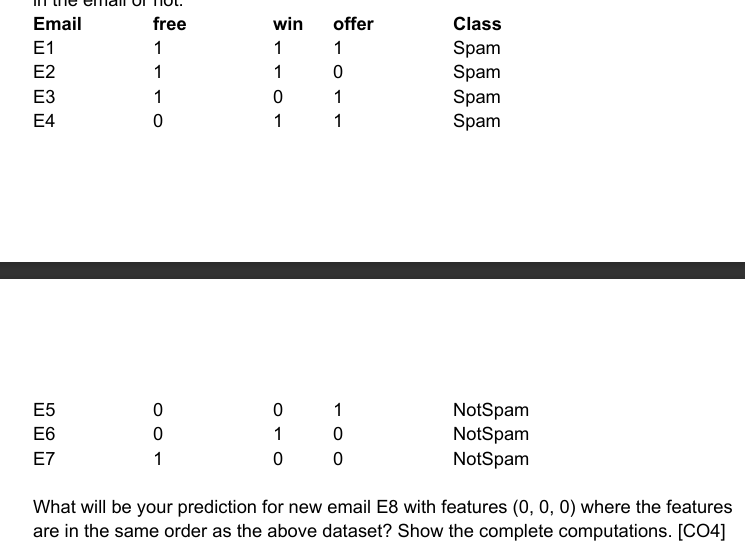

In [4]:
emails = [
    {"id": "E1", "features": (1, 1, 1), "class": "Spam"},
    {"id": "E2", "features": (1, 1, 0), "class": "Spam"},
    {"id": "E3", "features": (1, 0, 1), "class": "Spam"},
    {"id": "E4", "features": (0, 1, 1), "class": "Spam"},
    {"id": "E5", "features": (0, 0, 1), "class": "NotSpam"},
    {"id": "E6", "features": (0, 1, 0), "class": "NotSpam"},
    {"id": "E7", "features": (1, 0, 0), "class": "NotSpam"},
]
feature_names = ["free", "win", "offer"]
new_email = (0, 0, 0)
class_counts = Counter(email["class"] for email in emails)
class_results = {}

for label, class_count in class_counts.items():
    class_emails = [email for email in emails if email["class"] == label]
    feature_probabilities = {
        feature: sum(email["features"][index] for email in class_emails) / class_count
        for index, feature in enumerate(feature_names)
    }
    factors = {
        feature: (feature_probabilities[feature] if new_email[index] else 1 - feature_probabilities[feature])
        for index, feature in enumerate(feature_names)
    }
    likelihood = math.prod(factors.values())
    prior = class_count / len(emails)
    class_results[label] = {
        "class_count": class_count,
        "prior": prior,
        "feature_probabilities": feature_probabilities,
        "prediction_factors": factors,
        "likelihood": likelihood,
        "unnormalized_score": prior * likelihood,
    }

score_total = sum(result["unnormalized_score"] for result in class_results.values())
for result in class_results.values():
    result["posterior"] = result["unnormalized_score"] / score_total
prediction = max(class_results, key=lambda label: class_results[label]["unnormalized_score"])
q4_result = {
    "feature_order": feature_names,
    "email_E8": list(new_email),
    "class_calculations": class_results,
    "prediction": prediction,
}
print(json.dumps(q4_result, indent=2))
_ = save_json("q4_naive_bayes_results.json", q4_result)


{
  "feature_order": [
    "free",
    "win",
    "offer"
  ],
  "email_E8": [
    0,
    0,
    0
  ],
  "class_calculations": {
    "Spam": {
      "class_count": 4,
      "prior": 0.5714285714285714,
      "feature_probabilities": {
        "free": 0.75,
        "win": 0.75,
        "offer": 0.75
      },
      "prediction_factors": {
        "free": 0.25,
        "win": 0.25,
        "offer": 0.25
      },
      "likelihood": 0.015625,
      "unnormalized_score": 0.008928571428571428,
      "posterior": 0.0656934306569343
    },
    "NotSpam": {
      "class_count": 3,
      "prior": 0.42857142857142855,
      "feature_probabilities": {
        "free": 0.3333333333333333,
        "win": 0.3333333333333333,
        "offer": 0.3333333333333333
      },
      "prediction_factors": {
        "free": 0.6666666666666667,
        "win": 0.6666666666666667,
        "offer": 0.6666666666666667
      },
      "likelihood": 0.2962962962962964,
      "unnormalized_score": 0.126984126984127,
  

## Q5: Consider the following 5 sentences. Don’t add any start and end sentence markers. 
I like NLP 
I like AI 
You like NLP 
You love AI 
We love NLP 
 
Use Kneser-Ney smoothing to find out PKN(AI | love) and PKN(NLP | like). Use d = 0.5 in 
your computations.

In [5]:
sentences = [
    ["I", "like", "NLP"],
    ["I", "like", "AI"],
    ["You", "like", "NLP"],
    ["You", "love", "AI"],
    ["We", "love", "NLP"],
]
discount = 0.5
bigram_counts = Counter(
    (sentence[index], sentence[index + 1])
    for sentence in sentences
    for index in range(len(sentence) - 1)
)
context_counts = Counter()
context_followers = {}
word_predecessors = {}

for (context, word), count in bigram_counts.items():
    context_counts[context] += count
    context_followers.setdefault(context, set()).add(word)
    word_predecessors.setdefault(word, set()).add(context)

unique_bigram_count = len(bigram_counts)
continuation_probability = {
    word: len(predecessors) / unique_bigram_count
    for word, predecessors in word_predecessors.items()
}


def kneser_ney(context, word):
    count = bigram_counts[(context, word)]
    total = context_counts[context]
    distinct_followers = len(context_followers[context])
    discounted = max(count - discount, 0) / total
    backoff_weight = discount * distinct_followers / total
    continuation = continuation_probability.get(word, 0)
    return {
        "bigram_count": count,
        "context_count": total,
        "distinct_followers": distinct_followers,
        "discounted_probability": discounted,
        "backoff_weight": backoff_weight,
        "continuation_probability": continuation,
        "probability": discounted + backoff_weight * continuation,
    }


q5_result = {
    "discount": discount,
    "unique_bigram_count": unique_bigram_count,
    "continuation_probabilities": continuation_probability,
    "requested_probabilities": {
        "P(AI | love)": kneser_ney("love", "AI"),
        "P(NLP | like)": kneser_ney("like", "NLP"),
    },
}
print(json.dumps(q5_result, indent=2))
_ = save_json("q5_kneser_ney_results.json", q5_result)


{
  "discount": 0.5,
  "unique_bigram_count": 8,
  "continuation_probabilities": {
    "like": 0.25,
    "NLP": 0.25,
    "AI": 0.25,
    "love": 0.25
  },
  "requested_probabilities": {
    "P(AI | love)": {
      "bigram_count": 1,
      "context_count": 2,
      "distinct_followers": 2,
      "discounted_probability": 0.25,
      "backoff_weight": 0.5,
      "continuation_probability": 0.25,
      "probability": 0.375
    },
    "P(NLP | like)": {
      "bigram_count": 2,
      "context_count": 3,
      "distinct_followers": 2,
      "discounted_probability": 0.5,
      "backoff_weight": 0.3333333333333333,
      "continuation_probability": 0.25,
      "probability": 0.5833333333333334
    }
  }
}
